In [1]:
import traceback

import numpy as np
import pandas as pd
from aeon.forecasting.stats import AutoETS as AeonAutoETS
from aeon.forecasting.stats import ETS as AeonETS
from aeon.forecasting.utils._seasonality import calc_seasonal_period
from aeon.datasets import load_forecasting
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from aeon_benchmark.forecasting.arima import make_statsforecast_df
from statsforecast import StatsForecast
from statsforecast.models import AutoETS as SF_AutoETS
import warnings

from aeon_benchmark.forecasting.ets import make_ets_benchmark_presets, simulate_ets, generate_real_ets
warnings.filterwarnings("ignore")
import time, os
import matplotlib.pyplot as plt
import seaborn as sns

def compare_ets_forecasters(lengths, sigma=1.0, seed_base=0):
    """
    Compare forecasters over increasing serlsies lengths.

    Parameters
    ----------
    lengths : list of int
        Series lengths to evaluate.
    m : int
        Repetitions per length.
    sigma : float
        Std dev of noise in simulated data.
    seed_base : int
        Base seed to ensure reproducibility.

    Returns
    -------
    pandas.DataFrame
        Average MSE and time per method per length.
    """
    lists = load_forecasting("m4_monthly_dataset")['series_value']
    dataset = lists.apply(np.asarray)
    results = []
    # Warm up for numba
    n = 100
    y = generate_real_ets(dataset)
    aeon_model = AeonETS().fit(y)
    aeon_auto_model = AeonAutoETS().fit(y)
    df = make_statsforecast_df(y)
    m = calc_seasonal_period(y)
    sf = StatsForecast(models=[SF_AutoETS(season_length=m)], freq="H")
    forecast_df = sf.forecast(df=df, h=1)
    forecast = forecast_df.iloc[0]["AutoETS"]

    for n in lengths:
        print(" Beginning length ",n)
        for i in range(1000):
            # Generate parameters and data
            y = dataset[i]
            if (len(y)<n+1):
                continue
            seasonal_period = calc_seasonal_period(y)
            y_train = y[:-1]
            y_test = y[-1:]
            # --- Statsforecast AUTO---
            try:
                df = make_statsforecast_df(y_train)
                t0 = time.time()
                sf = StatsForecast(models=[SF_AutoETS()], freq="H")
                forecast_df = sf.forecast(df=df, h=1)
                sf_auto_forecast = forecast_df.iloc[0]["AutoETS"]
                t1 = time.time()
                error = y_test[0] - sf_auto_forecast
                sf_mse = float(error ** 2)
                results.append({"method": 'statsforecast_auto', "n": n, "mse": sf_mse, "time": t1-t0,"model": [seasonal_period]})
            except Exception as e:
                print("Stats forecast exception =  ",e)
            # --- Aeon AUTO---
            try:
                t0 = time.time()
                aeon_model = AeonAutoETS()
                forecast = aeon_model.forecast(y_train)
                t1 = time.time()
                error = y_test[0] - forecast
                mse = float(error ** 2)
                results.append({"method": 'aeon_auto', "n": n, "mse": mse, "time": t1-t0,"model": [seasonal_period]})
                if (mse-sf_mse)>50:
                    print("Occasionally Nelder-Mead fails terribly")
                    print({"method": 'aeon_auto', "n": n, "mse": mse, "sf_mse": sf_mse, "time": t1-t0,"aeon_model": aeon_model.wrapped_model_._model, "model": [seasonal_period]})
            except Exception as e:
                print("auto_aeon forecast exception =  ",e)
                traceback.print_exc()
    df_results = pd.DataFrame(results)
    return df_results

def plot_mse_and_runtime_by_library(df_results):
    """
    Plot MSE and total runtime for each library (statsmodels, statsforecast, aeon),
    separately for true and baseline models. Also print tables comparing
    statsforecast and aeon against statsmodels.

    Parameters
    ----------
    df_results : pd.DataFrame
        Must contain columns: ['method', 'n', 'mse', 'time']
    """
    sns.set(style="whitegrid", font_scale=1.2)
    df = df_results.copy()

    # Extract library and model type (true or baseline)
    df["library"] = df["method"].str.extract(r"^(statsforecast|statsmodels|aeon)")
    df["model_type"] = df["method"].str.extract(r"_(true|auto)")

    fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)

    for i, (metric, agg) in enumerate([("mse", "mean"), ("time", "sum")]):
        for j, model_type in enumerate(["true", "auto"]):
            ax = axes[i, j]
            data = df[df["model_type"] == model_type]

            summary = data.groupby(["library", "n"]).agg(
                mean=(metric, agg),
                std=(metric, "std")
            ).reset_index()

            sns.lineplot(
                data=summary,
                x="n",
                y="mean",
                hue="library",
                marker="o",
                err_style="band",
                err_kws={"alpha": 0.2},
                ax=ax
            )

            label = "Mean Squared Error" if metric == "mse" else "Total Runtime (seconds)"
            ax.set_title(f"{label} vs n ({model_type} models)")
            ax.set_xlabel("Series Length (n)")
            ax.set_ylabel(label)
            if metric == "time":
                ax.set_yscale("log")
            ax.grid(True)
            ax.legend(title="Library")

    plt.tight_layout()
    plt.show()

c:\dev\aeon\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
lists = load_forecasting("m4_monthly_dataset")['series_value']
dataset = lists.apply(np.asarray)
y = dataset[0]
aeon_model = AeonAutoETS()
y_train = y[:-1]
y_test = y[-1:]
forecast = aeon_model.forecast(y_train)
error = y_test[0] - forecast
mse = float(error ** 2)
print(forecast)
print(mse)
print(aeon_model.wrapped_model_.aic_)
print(aeon_model.wrapped_model_._model)
print(aeon_model.wrapped_model_.k_)
df = make_statsforecast_df(y_train)
sf = SF_AutoETS()
sf.fit(y=y_train)
forecast_df = sf.predict(h=1)
print(forecast_df)
sf_auto_forecast = forecast_df["mean"][0]
error = y_test[0] - sf_auto_forecast
mse = float(error ** 2)
print(sf_auto_forecast)
print(mse)
print(sf.model_)

4481.509838934759
222321.528212282
-461.5324931420786
[2 1 0 1]
4
{'mean': array([4490.0210068])}
4490.0210068024
230420.16697158958
{'loglik': -4802.671988069568, 'aic': 9611.343976139136, 'bic': np.float64(9623.902602010838), 'aicc': 9611.393768670257, 'mse': np.float64(788488.9186128831), 'amse': np.float64(1639125.0606520418), 'fit': results(x=array([9.99900000e-01, 8.00426494e+03]), fn=9605.343976139136, nit=26, simplex=array([[9.99900000e-01, 8.00426494e+03],
       [9.99900000e-01, 7.99360833e+03],
       [9.99900000e-01, 7.99130747e+03]])), 'residuals': array([-4.26493604e+00,  3.49999574e+02,  2.20035000e+02, -8.69977997e+02,
       -6.20086998e+02, -5.60062009e+02, -4.50056006e+02,  5.79954994e+02,
        1.80057995e+02, -1.11998199e+03, -4.50111998e+02,  2.09954989e+02,
        2.40002100e+03, -5.09759998e+02,  1.10994902e+03, -5.89889005e+02,
       -1.13005899e+03,  1.09886994e+02, -6.39989011e+02,  4.29936001e+02,
       -1.19995701e+03, -1.70119996e+02, -3.10017012e+02,

In [3]:
ets = AeonETS(error_type='additive', trend_type=None, seasonality_type=None, seasonal_period=1)
forecast = ets.forecast(y_train)
error = y_test[0] - forecast
mse = float(error ** 2)
print(mse)
print(ets.aic_)
print(ets.k_)
sf = SF_AutoETS()
sf.fit(y=y_train)
forecast_df = sf.predict(h=1)
sf_auto_forecast = forecast_df["mean"][0]
error = y_test[0] - sf_auto_forecast
mse = float(error ** 2)
print(sf_auto_forecast)
print(mse)
print(sf.model_)
sf = SF_AutoETS(season_length=5, model="AAA", damped=True)
sf.fit(y=y_train)
forecast_df = sf.predict(h=1)
sf_auto_forecast = forecast_df["mean"][0]
error = y_test[0] - sf_auto_forecast
mse = float(error ** 2)
print(sf_auto_forecast)
print(mse)
print(sf.model_)
print(y_test[0])

212889.32674494677
7961.35160498229
2
4490.0210068024
230420.16697158958
{'loglik': -4802.671988069568, 'aic': 9611.343976139136, 'bic': np.float64(9623.902602010838), 'aicc': 9611.393768670257, 'mse': np.float64(788488.9186128831), 'amse': np.float64(1639125.0606520418), 'fit': results(x=array([9.99900000e-01, 8.00426494e+03]), fn=9605.343976139136, nit=26, simplex=array([[9.99900000e-01, 8.00426494e+03],
       [9.99900000e-01, 7.99360833e+03],
       [9.99900000e-01, 7.99130747e+03]])), 'residuals': array([-4.26493604e+00,  3.49999574e+02,  2.20035000e+02, -8.69977997e+02,
       -6.20086998e+02, -5.60062009e+02, -4.50056006e+02,  5.79954994e+02,
        1.80057995e+02, -1.11998199e+03, -4.50111998e+02,  2.09954989e+02,
        2.40002100e+03, -5.09759998e+02,  1.10994902e+03, -5.89889005e+02,
       -1.13005899e+03,  1.09886994e+02, -6.39989011e+02,  4.29936001e+02,
       -1.19995701e+03, -1.70119996e+02, -3.10017012e+02,  5.79968998e+02,
        2.20005800e+03,  1.02200058e+01, -

In [4]:
results = compare_ets_forecasters(lengths=[200, 300, 400, 500, 600, 700, 800, 900, 1000],
                                    sigma=1.0, seed_base=0)

0
 Beginning length  200
Occasionally Nelder-Mead fails terribly
{'method': 'aeon_auto', 'n': 200, 'mse': 34552.348555393044, 'sf_mse': 33162.70865850218, 'time': 0.32916784286499023, 'aeon_model': array([2, 2, 0, 1], dtype=int32), 'model': [7]}
Occasionally Nelder-Mead fails terribly
{'method': 'aeon_auto', 'n': 200, 'mse': 20524.127153090198, 'sf_mse': 8891.894765205918, 'time': 0.44549059867858887, 'aeon_model': array([2, 1, 0, 1], dtype=int32), 'model': [9]}
Occasionally Nelder-Mead fails terribly
{'method': 'aeon_auto', 'n': 200, 'mse': 5713.600621044907, 'sf_mse': 3502.78797646333, 'time': 0.04343700408935547, 'aeon_model': array([2, 1, 0, 1], dtype=int32), 'model': [1]}
Occasionally Nelder-Mead fails terribly
{'method': 'aeon_auto', 'n': 200, 'mse': 1816.9131972373061, 'sf_mse': 1670.4972462169576, 'time': 0.06677556037902832, 'aeon_model': array([2, 1, 0, 1], dtype=int32), 'model': [1]}
Occasionally Nelder-Mead fails terribly
{'method': 'aeon_auto', 'n': 200, 'mse': 581.9487093

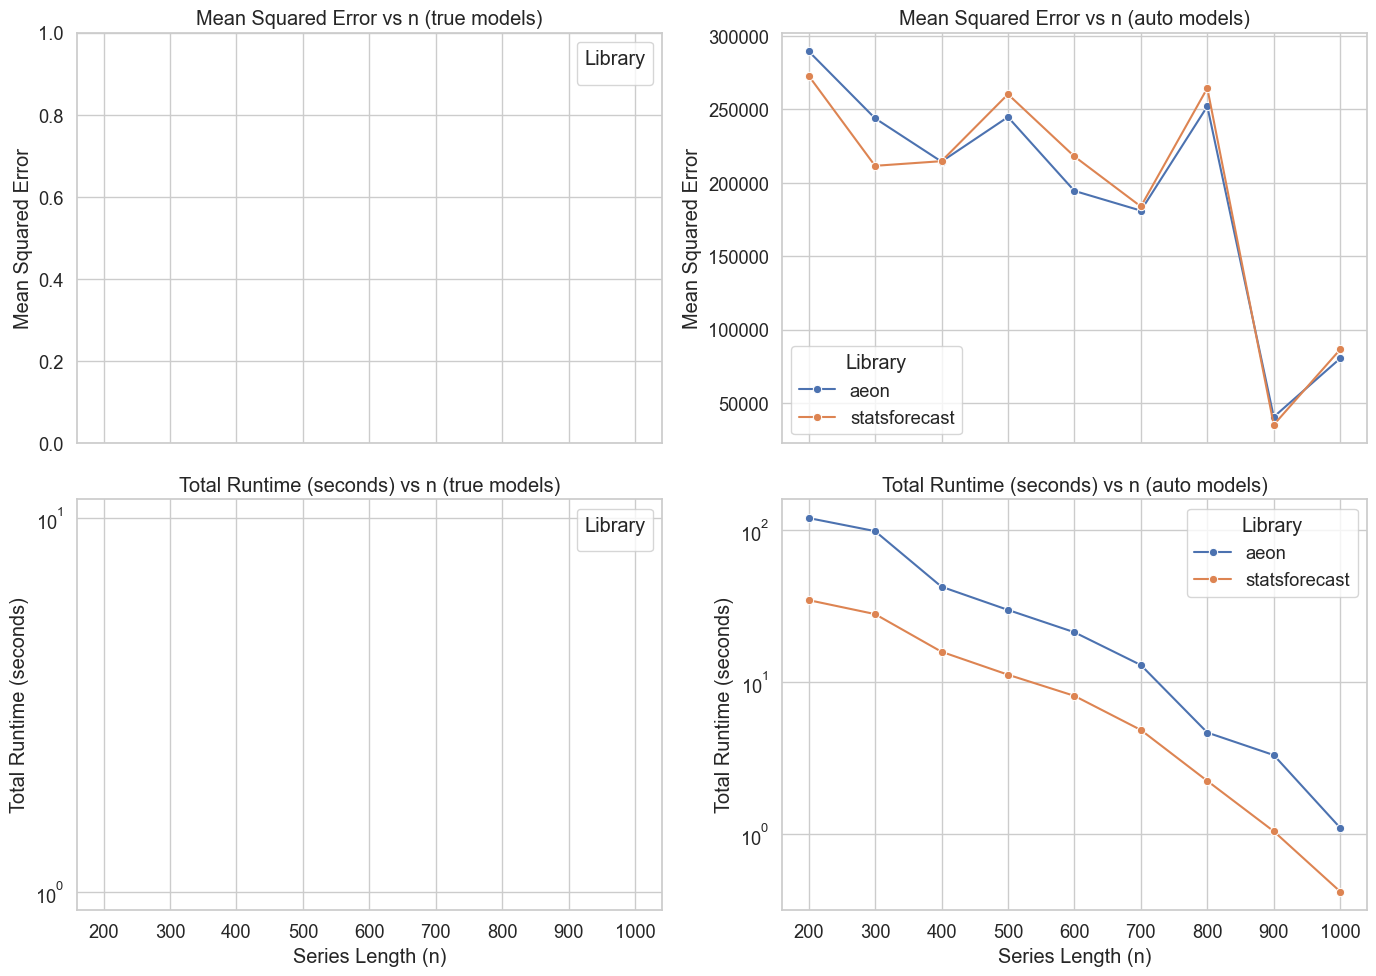

In [5]:
plot_mse_and_runtime_by_library(results)